<a href="https://www.kaggle.com/code/shedai/optiprophet-time-series-test?scriptVersionId=269973865" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# OptiTime-Prophet: Comprehensive Feature & Parameter Test (Revised)
**Last Updated:** 2025-10-22 12:39 UTC

**Changes in this revision:**
- Imports fixed to `from optitime import OptiProphet, available_datasets, load_dataset`.
- Initialization kwargs are **validated** against the class signature (no unexpected kwargs).
- Backtesting uses a **robust custom implementation** only (avoids API signature clashes).
- Metric computation aligns predictions and truth on the **intersection of dates** to avoid shape errors.
- Optional features (e.g., `growth='logistic'`, `quantiles`, external regressors) are **checked dynamically**.


This project is test case for : 
https://pypi.org/project/optitime-prophet/

Also home page : 
https://github.com/BilgisayarKavramlari/optitime

Massively inspired by 
https://www.OptiScorer.com a patented AI-Engine of OptiWisdom Inc.

In [1]:

pip -q install optitime-prophet


Note: you may need to restart the kernel to use updated packages.


## 1) Imports & Helpers

In [2]:
import warnings, inspect
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(12,4)

from optitime import OptiProphet, available_datasets, load_dataset

def filter_kwargs(cls, kwargs):
    sig = inspect.signature(cls.__init__)
    valid = set(p.name for p in sig.parameters.values())
    return {k:v for k,v in kwargs.items() if k in valid}

def line():
    print('-'*80)

def plot_series(df, title='Series', ds='ds', y='y'):
    plt.figure()
    plt.plot(df[ds], df[y])
    plt.title(title)
    plt.xlabel('date'); plt.ylabel(y)
    plt.show()

def plot_forecast(df_hist, df_fcst, title='Forecast', ds='ds', y='y', yhat='yhat', low='yhat_lower', up='yhat_upper'):
    plt.figure()
    if df_hist is not None:
        plt.plot(df_hist[ds], df_hist[y], label='observed')
    if yhat in df_fcst:
        plt.plot(df_fcst[ds], df_fcst[yhat], label='forecast')
    if low in df_fcst and up in df_fcst:
        plt.fill_between(df_fcst[ds], df_fcst[low], df_fcst[up], alpha=0.2, label='interval')
    plt.title(title)
    plt.xlabel('date'); plt.ylabel(y)
    plt.legend(); plt.show()

def eval_on_overlap(test_df, pred_df):
    merged = pd.merge(test_df[['ds','y']], pred_df[['ds','yhat']], on='ds', how='inner').dropna()
    y, yhat = merged['y'].values, merged['yhat'].values
    def mae(a,b): return float(np.mean(np.abs(a-b)))
    def rmse(a,b): return float(np.sqrt(np.mean((a-b)**2)))
    def mape(a,b): a=np.array(a); m=a!=0; return float(np.mean(np.abs((a[m]-b[m])/a[m]))*100) if m.any() else float('nan')
    return merged, {'MAE':mae(y,yhat),'RMSE':rmse(y,yhat),'MAPE':mape(y,yhat)}


## 2) Load Built-in Dataset (or Create Synthetic)

In [3]:
names = []
try:
    names = available_datasets()
    print('Available datasets:', names)
except Exception as e:
    print('[WARN] available_datasets() failed:', e)

loaded = {}
for nm in names:
    try:
        df = load_dataset(nm)
        assert {'ds','y'}.issubset(df.columns)
        loaded[nm] = df.sort_values('ds').reset_index(drop=True)
        print(f'Loaded {nm}: shape={df.shape}, range={df["ds"].min()}→{df["ds"].max()}')
    except Exception as e:
        print(f'[WARN] load_dataset({nm}) failed:', e)

if not loaded:
    print('[INFO] No built-in dataset; generating a synthetic series with weekly & yearly pattern.')
    rng = pd.date_range('2018-01-01','2021-12-31',freq='D')
    vals = 100 + 10*np.sin(2*np.pi*rng.dayofyear/365.25) + 5*np.sin(2*np.pi*rng.dayofweek/7) + np.random.randn(len(rng))*2
    loaded['synthetic_weekly'] = pd.DataFrame({'ds':rng,'y':vals})

list(loaded.keys())

Available datasets: ['air_passengers', 'airlines_traffic', 'shampoo_sales', 'us_acc_deaths']
Loaded air_passengers: shape=(144, 2), range=1949-01-01 00:00:00→1960-12-01 00:00:00
Loaded airlines_traffic: shape=(168, 3), range=2010-01-01 00:00:00→2023-12-01 00:00:00
Loaded shampoo_sales: shape=(36, 2), range=1901-01-01 00:00:00→1903-12-01 00:00:00
Loaded us_acc_deaths: shape=(72, 2), range=1973-01-01 00:00:00→1978-12-01 00:00:00


['air_passengers', 'airlines_traffic', 'shampoo_sales', 'us_acc_deaths']

## 3) Core Fit/Predict with Parameter Variants
We construct a parameter grid, then **filter unknown kwargs** before instantiation.


DATASET: air_passengers
--------------------------------------------------------------------------------


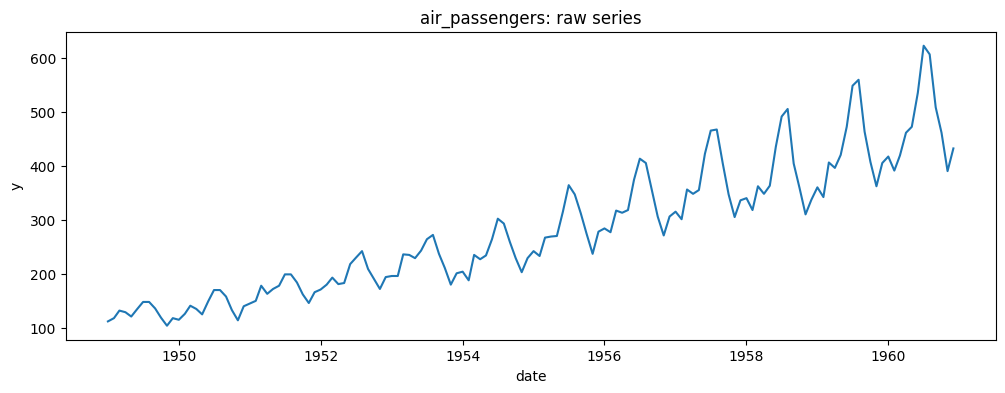

Config #1 (filtered): {'seasonality_mode': 'additive', 'interval_width': 0.9}


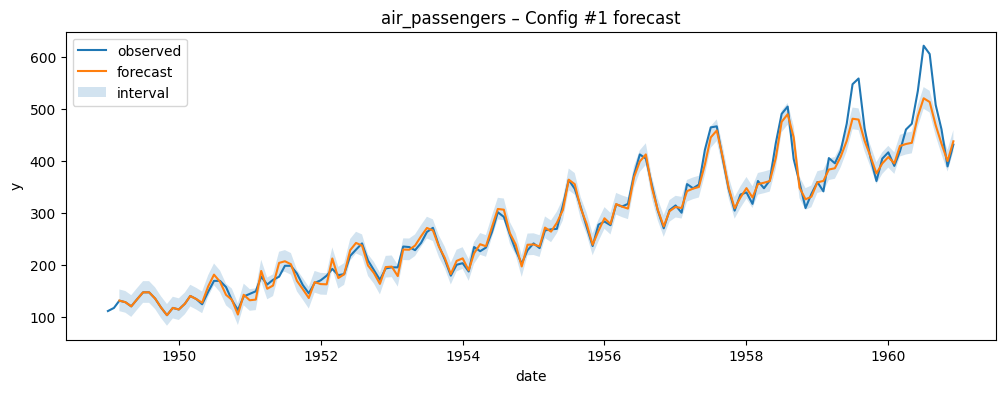

Test metrics on overlap: {'MAE': 31.105052611430768, 'RMSE': 42.14395777152211, 'MAPE': 6.074758396362023}
Config #2 (filtered): {'seasonality_mode': 'multiplicative', 'interval_width': 0.8}


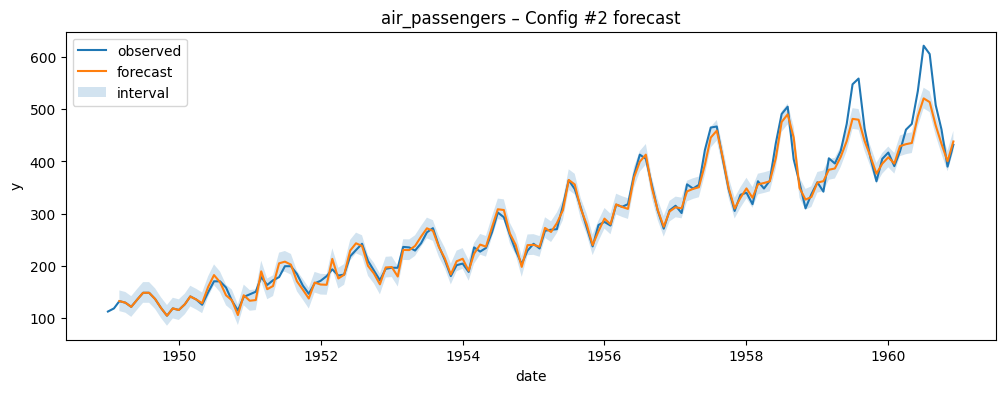

Test metrics on overlap: {'MAE': 31.105052611430768, 'RMSE': 42.14395777152211, 'MAPE': 6.074758396362023}
Config #3 (filtered): {'seasonality_mode': 'additive', 'interval_width': 0.9, 'ar_order': 7}


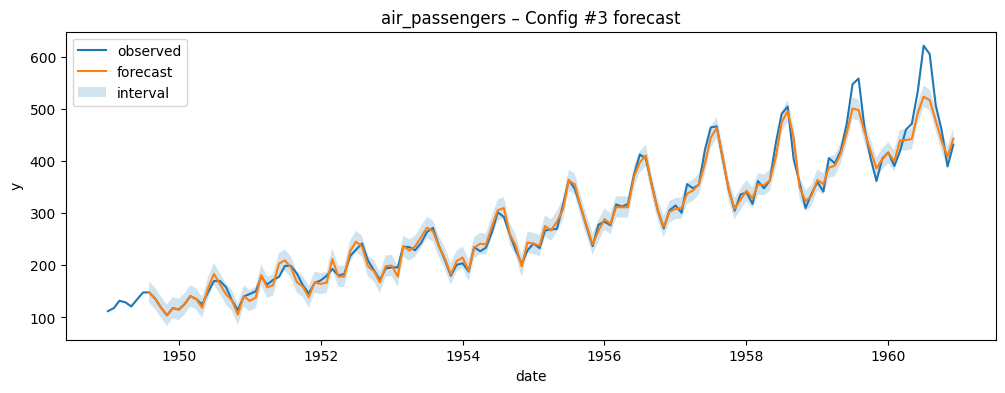

Test metrics on overlap: {'MAE': 26.820247273176598, 'RMSE': 37.05188022944792, 'MAPE': 5.287190647314219}
Config #4 (filtered): {'seasonality_mode': 'additive', 'interval_width': 0.9, 'quantiles': [0.1, 0.5, 0.9]}


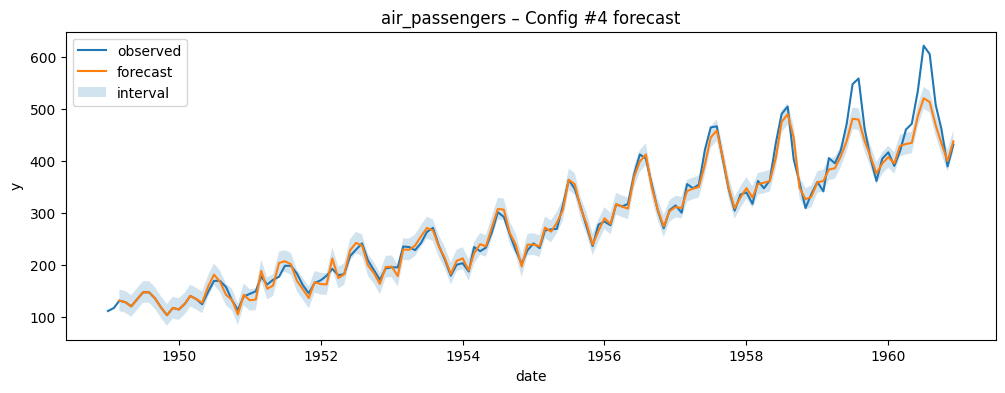

Test metrics on overlap: {'MAE': 31.105052611430768, 'RMSE': 42.14395777152211, 'MAPE': 6.074758396362023}

DATASET: airlines_traffic
--------------------------------------------------------------------------------


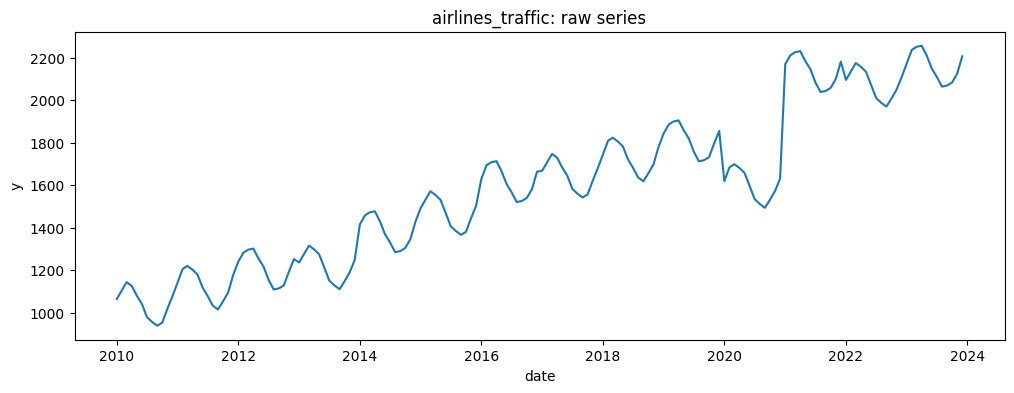

Config #1 (filtered): {'seasonality_mode': 'additive', 'interval_width': 0.9}


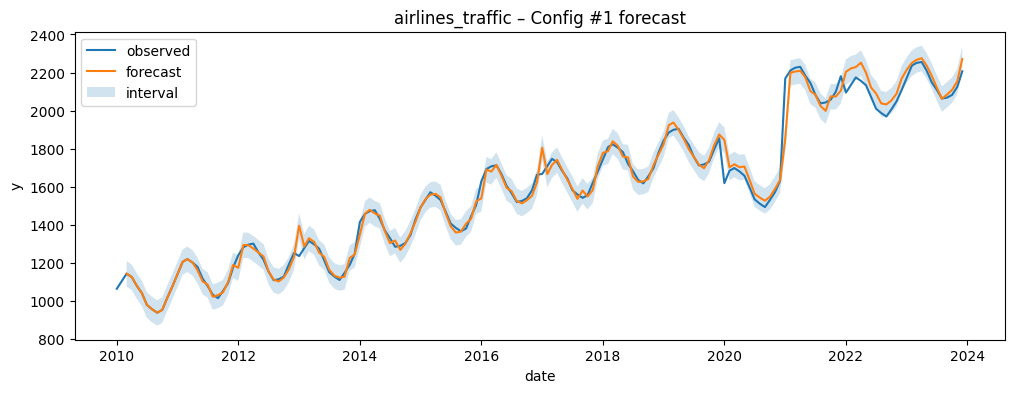

Test metrics on overlap: {'MAE': 46.41100449815353, 'RMSE': 53.9871875765148, 'MAPE': 2.201185473041035}
Config #2 (filtered): {'seasonality_mode': 'multiplicative', 'interval_width': 0.8}


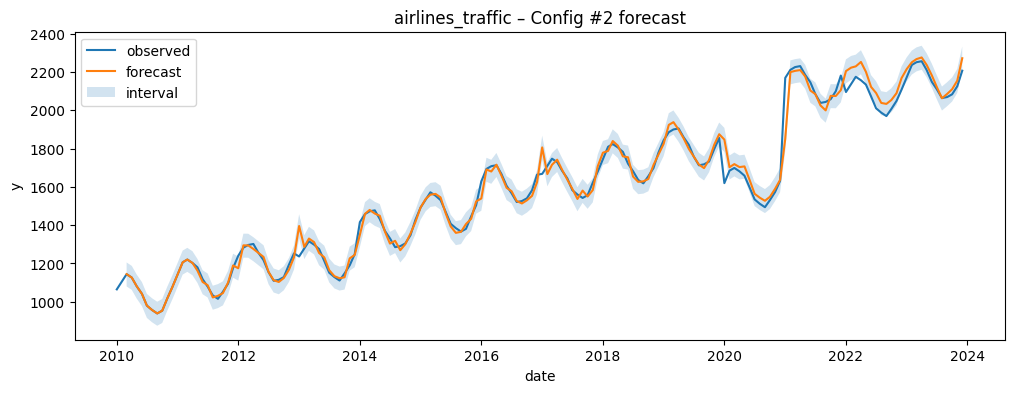

Test metrics on overlap: {'MAE': 46.41100449815353, 'RMSE': 53.9871875765148, 'MAPE': 2.201185473041035}
Config #3 (filtered): {'seasonality_mode': 'additive', 'interval_width': 0.9, 'ar_order': 7}


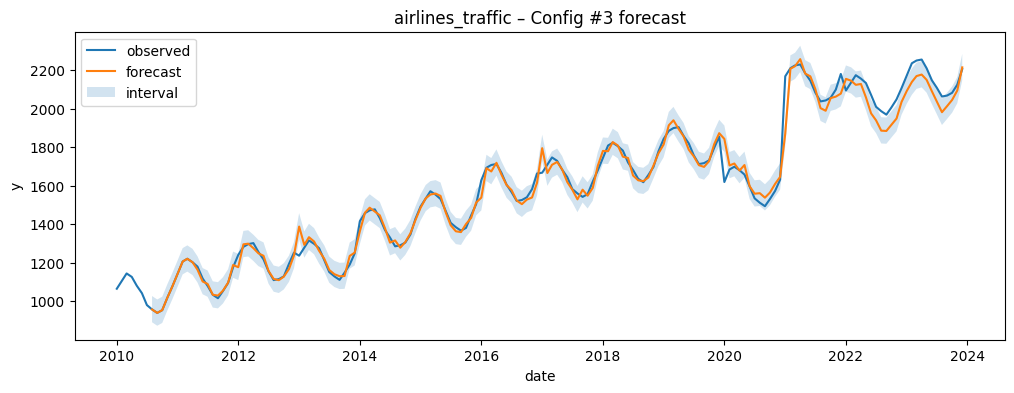

Test metrics on overlap: {'MAE': 65.66926716681175, 'RMSE': 70.99362671679143, 'MAPE': 3.114155072375282}
Config #4 (filtered): {'seasonality_mode': 'additive', 'interval_width': 0.9, 'quantiles': [0.1, 0.5, 0.9]}


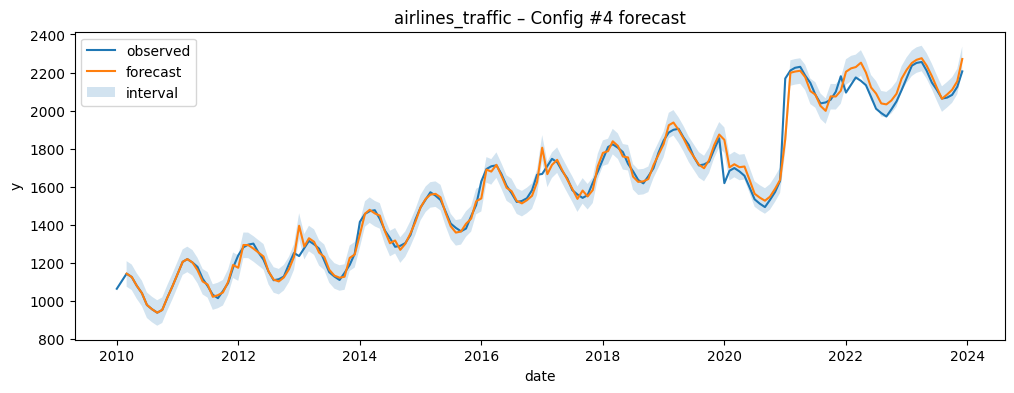

Test metrics on overlap: {'MAE': 46.41100449815353, 'RMSE': 53.9871875765148, 'MAPE': 2.201185473041035}

DATASET: shampoo_sales
--------------------------------------------------------------------------------


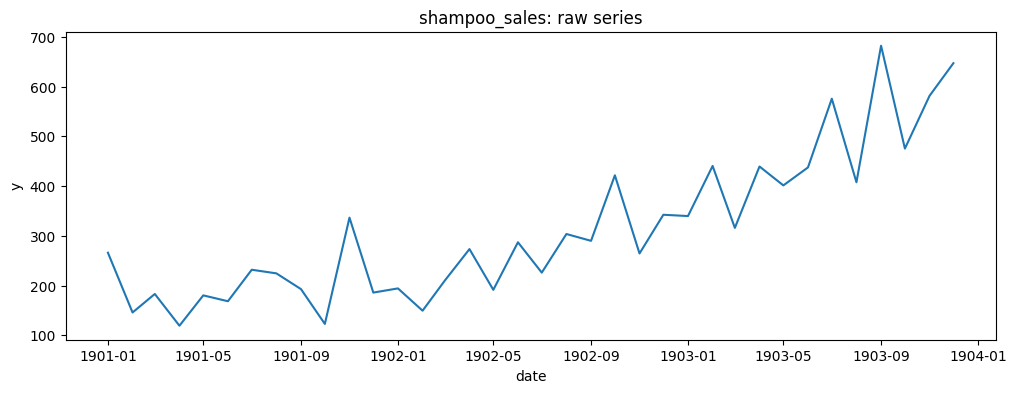

Config #1 (filtered): {'seasonality_mode': 'additive', 'interval_width': 0.9}


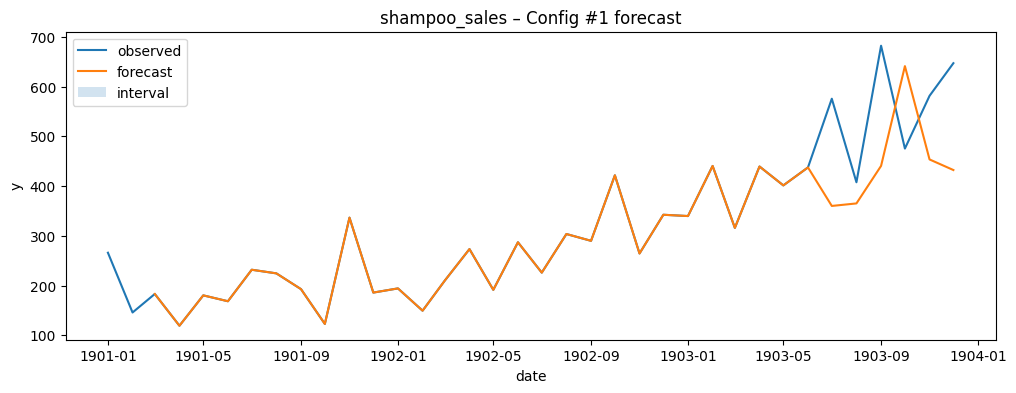

Test metrics on overlap: {'MAE': 167.96557041621693, 'RMSE': 180.96023175181455, 'MAPE': 28.88947635411861}
Config #2 (filtered): {'seasonality_mode': 'multiplicative', 'interval_width': 0.8}


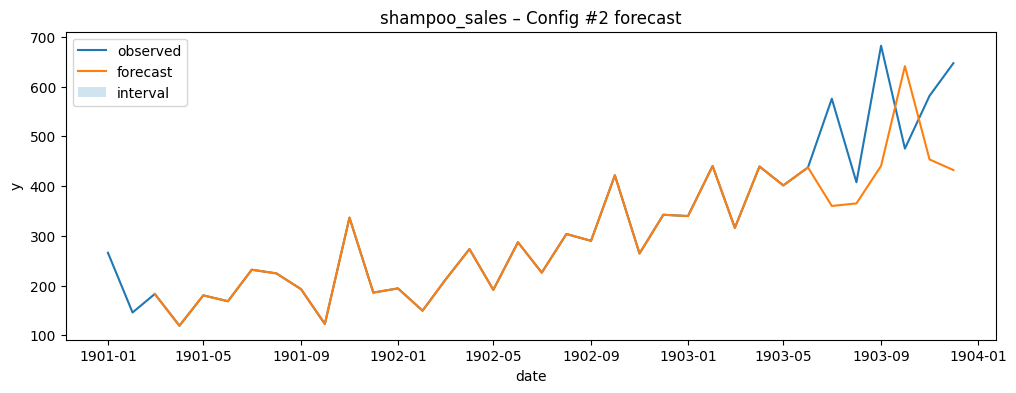

Test metrics on overlap: {'MAE': 167.96557041621693, 'RMSE': 180.96023175181455, 'MAPE': 28.88947635411861}
Config #3 (filtered): {'seasonality_mode': 'additive', 'interval_width': 0.9, 'ar_order': 7}


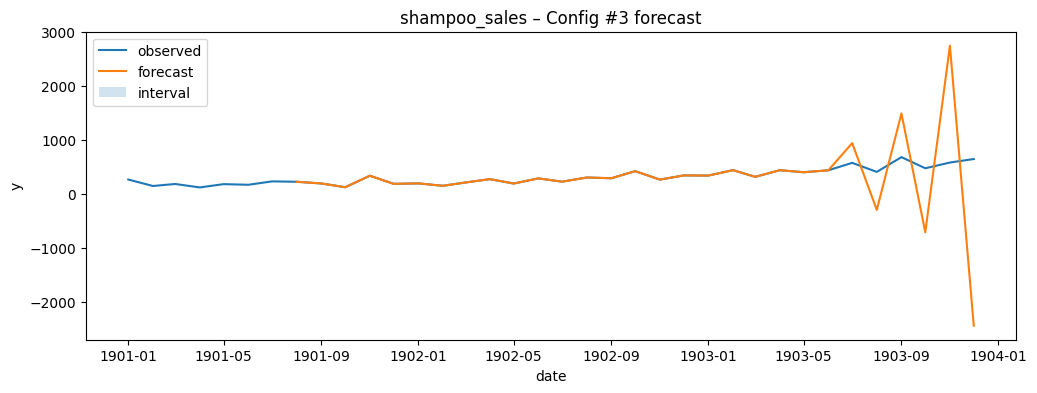

Test metrics on overlap: {'MAE': 1390.0698506779001, 'RMSE': 1683.4453553570288, 'MAPE': 243.02610320113192}
Config #4 (filtered): {'seasonality_mode': 'additive', 'interval_width': 0.9, 'quantiles': [0.1, 0.5, 0.9]}


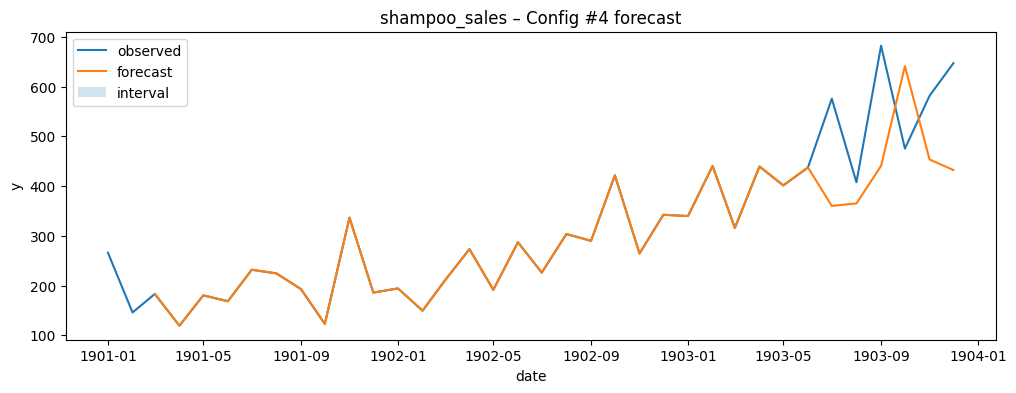

Test metrics on overlap: {'MAE': 167.96557041621693, 'RMSE': 180.96023175181455, 'MAPE': 28.88947635411861}

DATASET: us_acc_deaths
--------------------------------------------------------------------------------


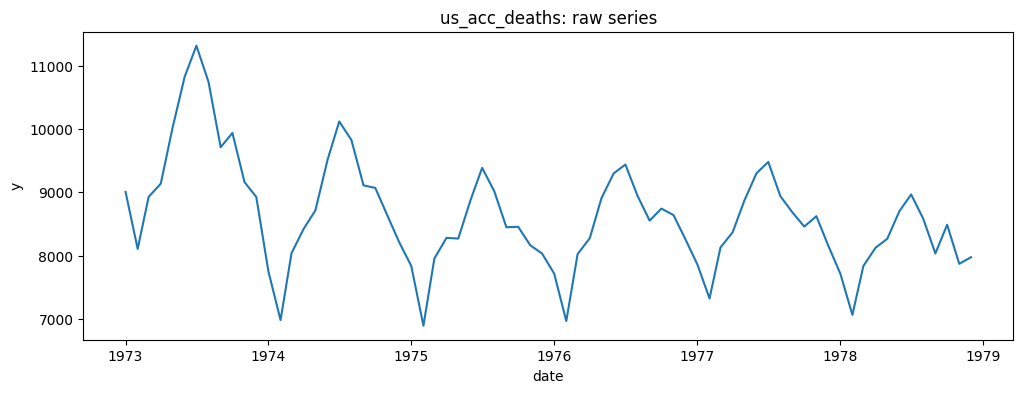

Config #1 (filtered): {'seasonality_mode': 'additive', 'interval_width': 0.9}


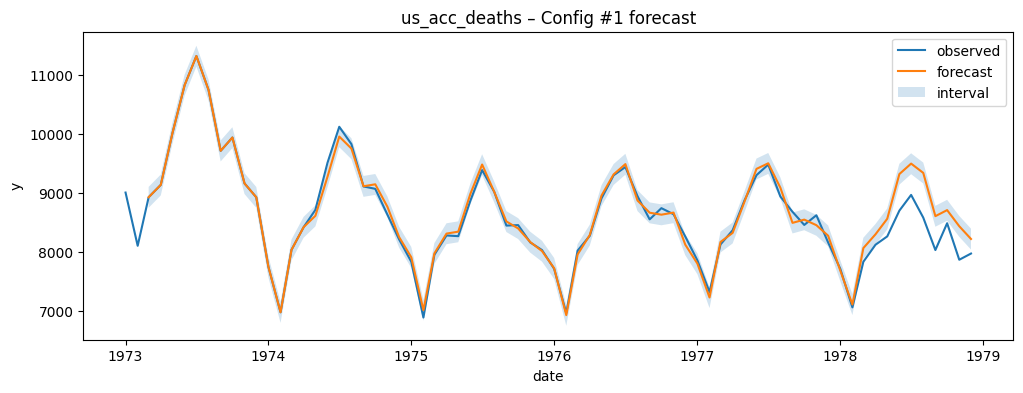

Test metrics on overlap: {'MAE': 388.1505705485986, 'RMSE': 444.4330832559368, 'MAPE': 4.665120718579465}
Config #2 (filtered): {'seasonality_mode': 'multiplicative', 'interval_width': 0.8}


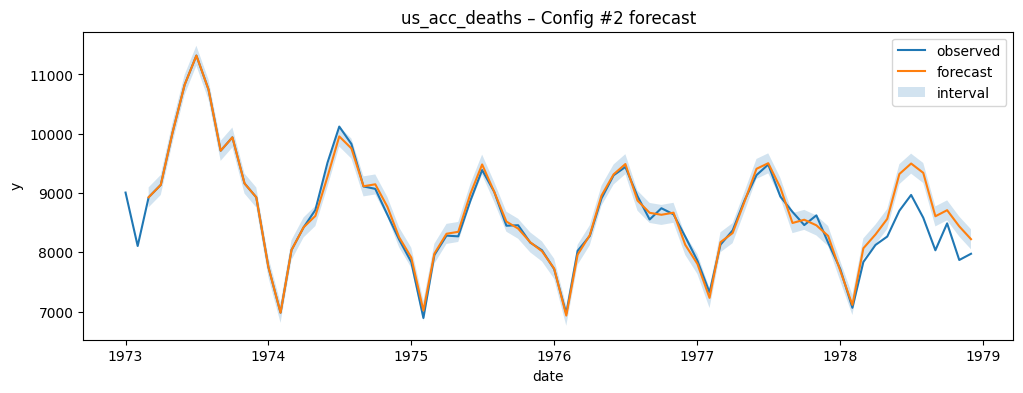

Test metrics on overlap: {'MAE': 388.1505705485986, 'RMSE': 444.4330832559368, 'MAPE': 4.665120718579465}
Config #3 (filtered): {'seasonality_mode': 'additive', 'interval_width': 0.9, 'ar_order': 7}


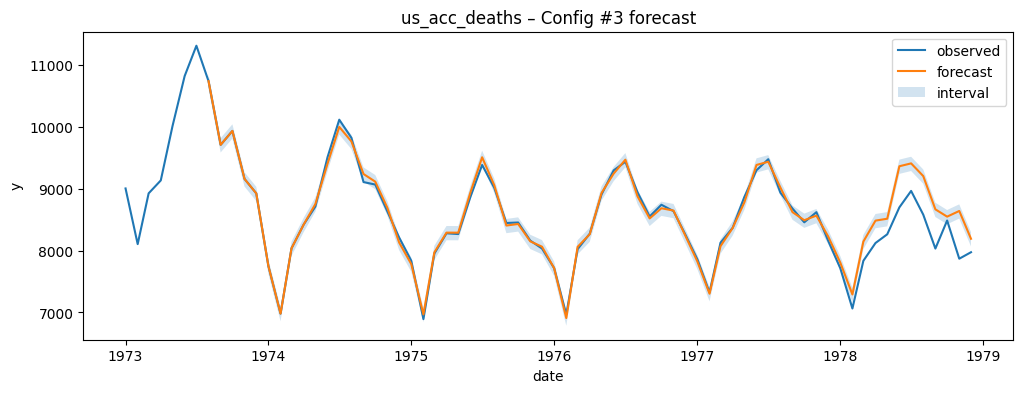

Test metrics on overlap: {'MAE': 415.99167060490237, 'RMSE': 469.5341465282078, 'MAPE': 5.07049796478681}
Config #4 (filtered): {'seasonality_mode': 'additive', 'interval_width': 0.9, 'quantiles': [0.1, 0.5, 0.9]}


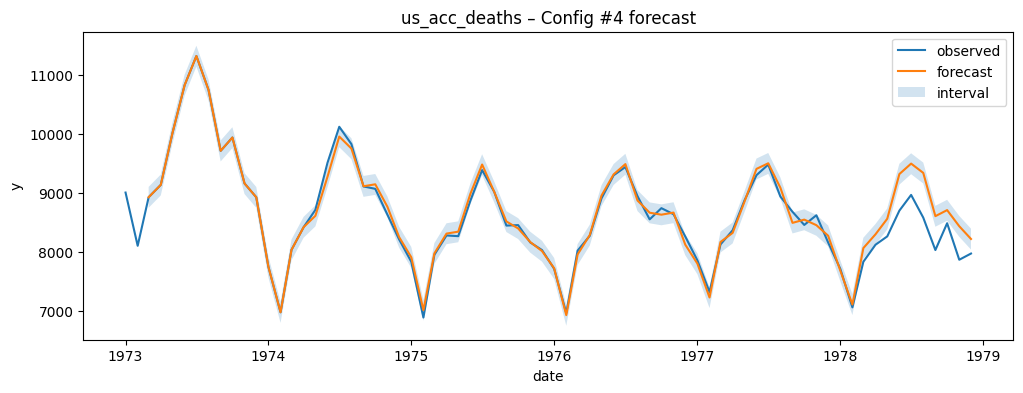

Test metrics on overlap: {'MAE': 388.1505705485986, 'RMSE': 444.4330832559368, 'MAPE': 4.665120718579465}


,dataset,config,seasonality_mode,interval_width,MAE,RMSE,MAPE,ar_order,quantiles
2,air_passengers,3,additive,0.9,26.820247,37.051880,5.287191,7.0,NaN
0,air_passengers,1,additive,0.9,31.105053,42.143958,6.074758,NaN,NaN
1,air_passengers,2,multiplicative,0.8,31.105053,42.143958,6.074758,NaN,NaN
3,air_passengers,4,additive,0.9,31.105053,42.143958,6.074758,NaN,"[0.1, 0.5, 0.9]"
4,airlines_traffic,1,additive,0.9,46.411004,53.987188,2.201185,NaN,NaN
5,airlines_traffic,2,multiplicative,0.8,46.411004,53.987188,2.201185,NaN,NaN
7,airlines_traffic,4,additive,0.9,46.411004,53.987188,2.201185,NaN,"[0.1, 0.5, 0.9]"
6,airlines_traffic,3,additive,0.9,65.669267,70.993627,3.114155,7.0,NaN
8,shampoo_sales,1,additive,0.9,167.965570,180.960232,28.889476,NaN,NaN
9,shampoo_sales,2,multiplicative,0.8,167.965570,180.960232,28.889476,NaN,NaN


In [4]:
raw_param_grid = [
    {'seasonality_mode':'additive','interval_width':0.9},
    {'seasonality_mode':'multiplicative','interval_width':0.8},
    {'seasonality_mode':'additive','interval_width':0.9,'ar_order':7},   # only used if supported
    {'seasonality_mode':'additive','interval_width':0.9,'quantiles':[0.1,0.5,0.9]},  # if supported
]

results = []
for name, df in loaded.items():
    print('\nDATASET:', name); line(); plot_series(df, f'{name}: raw series')
    split = int(len(df)*0.85)
    train, test = df.iloc[:split].copy(), df.iloc[split:].copy()
    for i,params in enumerate(raw_param_grid,1):
        valid_params = filter_kwargs(OptiProphet, params)
        print(f'Config #{i} (filtered):', valid_params)
        model = OptiProphet(**valid_params)
        model.fit(train)
        freq = pd.infer_freq(df['ds']) or 'D'
        future = pd.DataFrame({'ds': pd.date_range(train['ds'].min(), test['ds'].max(), freq=freq)})
        fcst = model.predict(future)
        plot_forecast(pd.concat([train,test]), fcst, title=f'{name} – Config #{i} forecast')
        overlap, met = eval_on_overlap(test, fcst)
        print('Test metrics on overlap:', met)
        results.append({'dataset':name,'config':i, **valid_params, **met})

res_df = pd.DataFrame(results)
res_df.sort_values(['dataset','RMSE']).head(20)

## 4) Logistic Growth with `cap`/`floor` (if supported)

In [5]:
name, df0 = list(loaded.items())[0]
sig = inspect.signature(OptiProphet.__init__)
if 'growth' in sig.parameters:
    df_l = df0.copy()
    df_l['y'] = (df_l['y'] - df_l['y'].min())
    cap = df_l['y'].quantile(0.95) + 5
    df_l['cap'] = cap; df_l['floor'] = 0
    try:
        model = OptiProphet(**filter_kwargs(OptiProphet, {'growth':'logistic','interval_width':0.9}))
        model.fit(df_l)
        future = df_l[['ds']].copy(); future['cap']=cap; future['floor']=0
        fcst = model.predict(future)
        plot_forecast(df_l, fcst, title=f'{name}: logistic growth with cap/floor')
    except Exception as e:
        print('[INFO] Logistic growth path failed:', e)
else:
    print('[INFO] growth parameter not supported; skipping logistic test.')

[INFO] growth parameter not supported; skipping logistic test.


## 5) External Regressors (if supported)

In [6]:
df_reg = list(loaded.values())[0].copy()
df_reg['is_weekend'] = (df_reg['ds'].dt.weekday>=5).astype(int)
m = OptiProphet(**filter_kwargs(OptiProphet, {'interval_width':0.9}))
if hasattr(m,'add_regressor'):
    try:
        m.add_regressor('is_weekend')
        m.fit(df_reg)
        future = df_reg[['ds','is_weekend']].copy()
        fc = m.predict(future)
        plot_forecast(df_reg, fc, title='With external regressor: weekend flag')
    except Exception as e:
        print('[INFO] External regressor path failed:', e)
else:
    print('[INFO] add_regressor not exposed; skipping external regressor test.')

[INFO] add_regressor not exposed; skipping external regressor test.


## 6) Rolling-Origin Backtest (Robust)

In [7]:
def simple_backtest(df, horizon=28, step=28, min_train=365, model_kwargs=None):
    if model_kwargs is None: model_kwargs = {}
    df=df.sort_values('ds').reset_index(drop=True)
    out=[]; start=min_train if len(df)>min_train+horizon else int(len(df)*0.6)
    while start+horizon<=len(df):
        tr=df.iloc[:start]; te=df.iloc[start:start+horizon]
        m=OptiProphet(**filter_kwargs(OptiProphet, model_kwargs))
        m.fit(tr)
        fut=te[['ds']].copy()
        pr=m.predict(fut)
        merged = te.merge(pr[['ds','yhat']], on='ds', how='inner').dropna()
        y, yhat = merged['y'].values, merged['yhat'].values
        def mae(a,b): return float(np.mean(np.abs(a-b)))
        def rmse(a,b): return float(np.sqrt(np.mean((a-b)**2)))
        def mape(a,b): a=np.array(a); m=a!=0; return float(np.mean(np.abs((a[m]-b[m])/a[m]))*100) if m.any() else float('nan')
        out.append({'cutoff':str(tr['ds'].max().date()), 'MAE':mae(y,yhat), 'RMSE':rmse(y,yhat), 'MAPE':mape(y,yhat)})
        start+=step
    return pd.DataFrame(out)

name, df0 = list(loaded.items())[0]
bt = simple_backtest(df0, horizon=28, step=28, min_train=365, model_kwargs={'interval_width':0.9})
bt

,cutoff,MAE,RMSE,MAPE
0,1956-02-01,25.760422,36.264032,6.559146
1,1958-06-01,30.381742,38.570981,6.634662


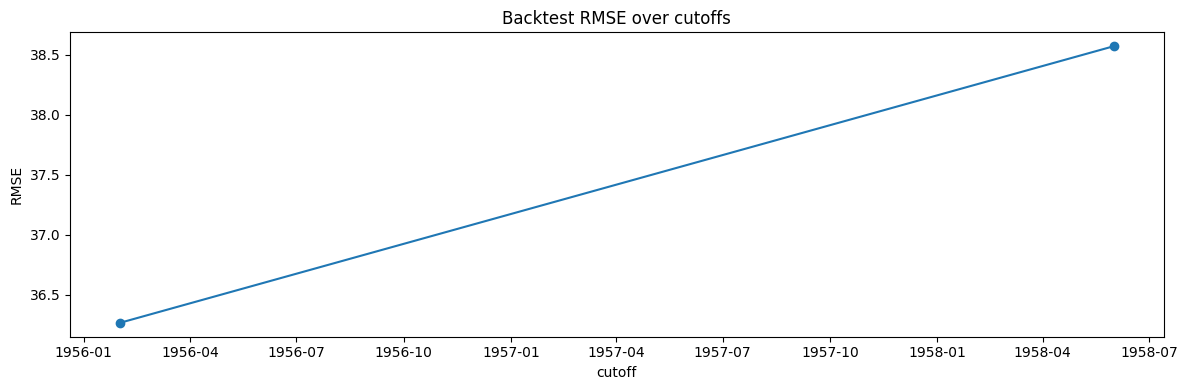

In [8]:
plt.figure()
try:
    x = pd.to_datetime(bt['cutoff'])
except Exception:
    x = np.arange(len(bt))
plt.plot(x, bt['RMSE'], marker='o')
plt.title('Backtest RMSE over cutoffs')
plt.xlabel('cutoff'); plt.ylabel('RMSE')
plt.tight_layout(); plt.show()

## 7) Components & Report (If Exposed)

In [9]:
m = OptiProphet(**filter_kwargs(OptiProphet, {'interval_width':0.9}))
name, df0 = list(loaded.items())[0]
m.fit(df0)
fc = m.predict(df0[['ds']].copy())

if hasattr(m,'history_components'):
    try:
        comps = m.history_components()
        if isinstance(comps, dict):
            for k,v in comps.items():
                if isinstance(v, pd.DataFrame) and {'ds','value'}.issubset(v.columns):
                    plt.figure(); plt.plot(v['ds'], v['value'])
                    plt.title(f'Component: {k}')
                    plt.xlabel('date'); plt.ylabel('contribution')
                    plt.show()
    except Exception as e:
        print('[INFO] history_components() failed:', e)
elif hasattr(m,'components_'):
    try:
        for k,v in m.components_.items():
            if isinstance(v, pd.DataFrame) and {'ds','value'}.issubset(v.columns):
                plt.figure(); plt.plot(v['ds'], v['value'])
                plt.title(f'Component: {k}')
                plt.xlabel('date'); plt.ylabel('contribution')
                plt.show()
    except Exception as e:
        print('[INFO] components_ rendering failed:', e)
else:
    print('[INFO] No components API exposed.')

if hasattr(m,'report'):
    try:
        rep = m.report()
        print('Model report:')
        print(rep)
    except Exception as e:
        print('[INFO] report() failed:', e)
else:
    print('No report() method exposed.')

Model report:
{'metrics': {'mae': 9.059357248182941, 'mse': 147.3272388619435, 'rmse': 12.13784325413471, 'mape': 3.4795306447869234, 'r2': 0.9895533947776131}, 'component_strength': {'trend': 0.1514678046744885, 'seasonality': 0.07203017926781485, 'regressors': 0.0, 'autoregressive': 0.7764788584309725, 'moving_average': 2.3157626724055806e-05}, 'changepoints': ['1949-06-01T00:00:00', '1949-09-01T00:00:00', '1949-08-01T00:00:00', '1949-12-01T00:00:00', '1950-05-01T00:00:00', '1950-02-01T00:00:00', '1949-03-01T00:00:00', '1949-04-01T00:00:00', '1949-10-01T00:00:00', '1949-07-01T00:00:00', '1950-04-01T00:00:00', '1949-11-01T00:00:00', '1950-01-01T00:00:00', '1949-05-01T00:00:00', '1950-03-01T00:00:00'], 'outliers': [{'timestamp': '1958-09-01T00:00:00', 'residual': -37.26802714604719}, {'timestamp': '1960-07-01T00:00:00', 'residual': 42.84427076404813}], 'comments': []}


## 8) Exception Handling (Sanity Checks)

In [10]:
# Empty dataset
try:
    m = OptiProphet()
    m.fit(pd.DataFrame({'ds':[], 'y':[]}))
    print('[WARN] Empty dataset did not raise. Consider raising a DataValidationError in the library.')
except Exception as e:
    print('Empty dataset raised:', type(e).__name__, '-', e)

# Insufficient data
short_df = pd.DataFrame({'ds': pd.date_range('2020-01-01', periods=3, freq='D'), 'y':[1.0, np.nan, 2.0]})
try:
    m = OptiProphet()
    m.fit(short_df)
    print('[WARN] Short dataset did not raise. Consider an InsufficientDataError in the library.')
except Exception as e:
    print('Short dataset raised:', type(e).__name__, '-', e)

# Low-quality forecast path (if library exposes a quality validator)
try:
    rng = pd.date_range('2019-01-01','2020-12-31',freq='D')
    df_bad = pd.DataFrame({'ds':rng, 'y': np.random.randn(len(rng))})
    m = OptiProphet(**filter_kwargs(OptiProphet, {'interval_width':0.9}))
    m.fit(df_bad)
    pr = m.predict(df_bad[['ds']])
    if hasattr(m,'validate_quality'):
        try:
            m.validate_quality(pr)
            print('validate_quality() executed.')
        except Exception as e2:
            print('validate_quality raised:', type(e2).__name__, '-', e2)
    else:
        print('[INFO] No validate_quality API; skipping low-quality assertion.')
except Exception as e:
    print('Low-quality path raised:', type(e).__name__, '-', e)


Empty dataset raised: DataValidationError - Cannot fit model on an empty dataset.
Short dataset raised: DataValidationError - Insufficient data points (3). At least 30 observations are required.
Low-quality path raised: ForecastQualityError - Model fit quality insufficient (R2=0.043 < 0.1).
